In [36]:
import numpy as np
import scipy.io
import pandas as pd
import anndata as ad

# ── 1. Load CellOracle A matrix ────────────────────────────────────────────────
BASE = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
CO   = f"{BASE}/cell_oracle_run/cell_oracle_global_A"

A      = np.load(f"{CO}/A_celloracle.npy")
A_genes = np.load(f"{CO}/A_genes.npy", allow_pickle=True)
A_tfs   = np.load(f"{CO}/A_tfs.npy",   allow_pickle=True)
print("A shape:", A.shape)  # (n_tfs, n_genes)

# ── 2. Load RNA ─────────────────────────────────────────────────────────────────
adata      = ad.read_h5ad(f"{BASE}/velten_rna.h5ad")
gene_names = list(adata.var_names)
g2i        = {g: i for i, g in enumerate(gene_names)}
X_full     = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X

# ── 3. Align A to RNA gene space ────────────────────────────────────────────────
gene_mask = np.array([g in g2i for g in A_genes])
A         = A[:, gene_mask]
A_genes   = A_genes[gene_mask]

# Keep only TFs that are also in the gene list
tf_in_genes_mask = np.array([t in set(A_genes) for t in A_tfs])
A     = A[tf_in_genes_mask, :]
A_tfs = A_tfs[tf_in_genes_mask]

print("A aligned:", A.shape)

# Gene/TF indices into the full RNA matrix
gene_idx = np.array([g2i[g] for g in A_genes])
sub_g2i  = {g: i for i, g in enumerate(A_genes)}
tf_idx   = np.array([sub_g2i[t] for t in A_tfs])

X     = X_full[:, gene_idx]   # (cells, n_genes_kept)
X_TF  = X[:, tf_idx]          # (cells, n_tfs_kept)

# ── 4. Build M (genes x TFs), aligned to A_genes / A_tfs ──────────────────────
peak_tf  = scipy.io.mmread(f"{BASE}/peak_tf.mtx").tocsr()   # (peaks, n_motif_tfs)
tf_names = open(f"{BASE}/tf_names.txt").read().strip().split()
assert peak_tf.shape[1] == len(tf_names), "peak_tf col mismatch"

peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")  # cols: peak, gene
peaks     = pd.read_csv(f"{BASE}/peaks.txt", header=None)[0].astype(str).tolist()

peak_to_idx = {p: i for i, p in enumerate(peaks)}

# Build sparse peak x gene matrix (only for genes in A_genes)
from scipy.sparse import lil_matrix
P = len(peaks)
G = len(A_genes)

peak_gene_mat = lil_matrix((P, G))
for _, row in peak_gene.iterrows():
    p, g = row["peak"], row["gene"]
    if p in peak_to_idx and g in sub_g2i:
        peak_gene_mat[peak_to_idx[p], sub_g2i[g]] = 1
peak_gene_mat = peak_gene_mat.tocsr()

# M: (n_genes_kept, n_motif_tfs)  — which TF motifs are accessible near each gene
M_full = (peak_gene_mat.T @ peak_tf)
M_full = (M_full > 0).astype(np.float32)

# Now filter columns to only the TFs present in A_tfs
t2i    = {t: i for i, t in enumerate(tf_names)}
tf_col = np.array([t2i[t] for t in A_tfs if t in t2i])
tf_ok  = np.array([t in t2i for t in A_tfs])

# Drop A_tfs not found in motif set (rare, but safe)
A     = A[tf_ok, :]
A_tfs = A_tfs[tf_ok]
X_TF  = X_TF[:, tf_ok]
tf_idx = tf_idx[tf_ok]

M = np.array(M_full[:, tf_col].todense())   # (n_genes_kept, n_tfs_kept)
print(f"M shape: {M.shape}  A shape: {A.shape}")
# Both should be (n_genes_kept, n_tfs_kept) / (n_tfs_kept, n_genes_kept)
assert M.shape == (len(A_genes), len(A_tfs))

A shape: (277, 2995)
A aligned: (271, 2995)
M shape: (2995, 271)  A shape: (271, 2995)


In [37]:
# ── 5. Model ───────────────────────────────────────────────────────────────────
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

X_t    = torch.tensor(X,    dtype=torch.float32)
X_TF_t = torch.tensor(X_TF, dtype=torch.float32)

pca    = PCA(n_components=50, random_state=42)
nn_mdl = NearestNeighbors(n_neighbors=30).fit(pca.fit_transform(X))
nn_idx_t = torch.tensor(nn_mdl.kneighbors(pca.transform(X), return_distance=False), dtype=torch.long)

class RegulatoryFlowModel(nn.Module):
    def __init__(self, G, T, K, M):
        super().__init__()
        self.U = nn.Parameter(torch.randn(G, K) * 0.01)
        self.V = nn.Parameter(torch.randn(T, K) * 0.01)
        M_t = torch.tensor(M, dtype=torch.float32)
        M_t = M_t / (M_t.max() + 1e-8)
        self.register_buffer("M", M_t)   # (G, T)

    def forward(self, X_TF):
        A_raw = self.U @ self.V.T          # (G, T)
        A     = A_raw * torch.sigmoid(10.0 * self.M)
        return X_TF @ A.T, A              # V_pred: (cells, G)

def cosine_loss(V_pred, X_t, nn_idx_t):
    v  = F.normalize(V_pred, dim=1)
    loss = 0.0
    for k in range(nn_idx_t.shape[1]):
        d = F.normalize(X_t[nn_idx_t[:, k]] - X_t, dim=1)
        loss -= (v * d).sum(dim=1).mean()
    return loss / nn_idx_t.shape[1]

In [38]:
G, T, K = X.shape[1], X_TF.shape[1], 20
model = RegulatoryFlowModel(G=G, T=T, K=K, M=M)
opt   = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(300):
    opt.zero_grad()
    V_pred, A_learned = model(X_TF_t)
    loss = cosine_loss(V_pred, X_t, nn_idx_t) + 1e-3 * (model.U.pow(2).mean() + model.V.pow(2).mean())
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    if epoch % 30 == 0:
        print(epoch, loss.item())

0 0.001122252899222076
30 -0.19604334235191345
60 -0.26949262619018555
90 -0.3005312979221344
120 -0.3140227794647217
150 -0.32021209597587585
180 -0.3238513171672821
210 -0.3258829712867737
240 -0.32702121138572693
270 -0.32762446999549866


In [40]:
with torch.no_grad():
    V_pred, A_learned = model(X_TF_t)

np.save("uv_mask/V_pred_learned.npy", V_pred.numpy())
np.save("uv_mask/A_learned.npy", A_learned.numpy())
np.save("uv_mask/U.npy", model.U.detach().numpy())
np.save("uv_mask/V.npy", model.V.detach().numpy())

/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


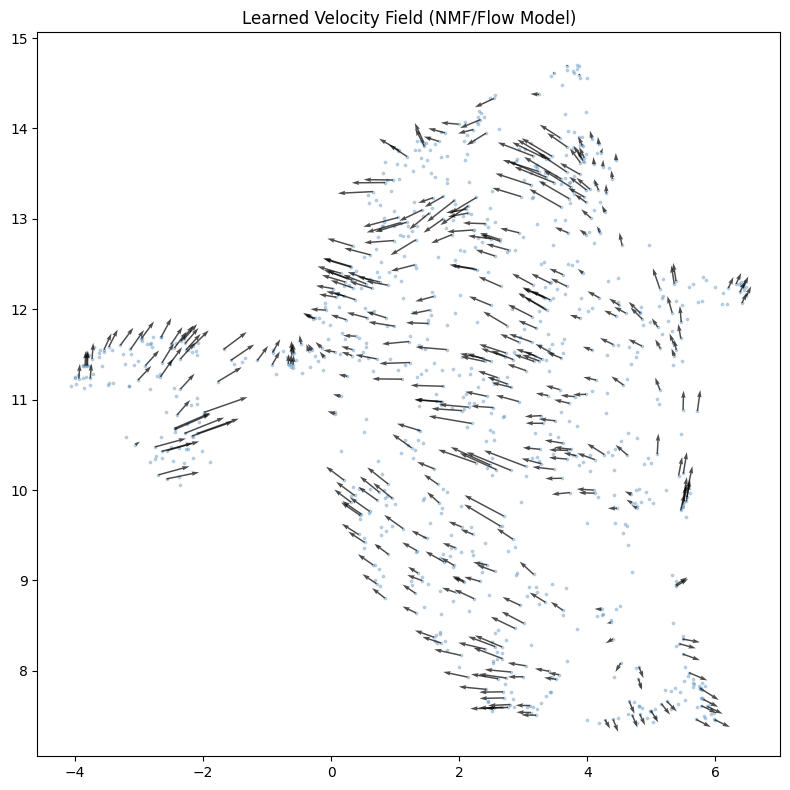

Velocity–pseudotime alignment: 0.13655080176361367


In [41]:
# visualize_velocity.py (UPDATED FOR LEARNED MODEL)

import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from umap import UMAP
from scipy.stats import spearmanr

# =========================
# 1. LOAD DATA
# =========================
adata = ad.read_h5ad(
    "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/velten_rna.h5ad"
)

V_pred = np.load("uv_mask/V_pred_learned.npy")   # <-- UPDATED NAME
gene_idx = np.load("gene_idx.npy")

X_full = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X

# =========================
# 2. ALIGN X TO MODEL SPACE
# =========================
X = X_full[:, gene_idx]

assert X.shape == V_pred.shape, "Mismatch between X and V_pred"

# =========================
# 3. UMAP EMBEDDING
# =========================
reducer = UMAP(n_neighbors=15, random_state=42)
X_umap = reducer.fit_transform(X)

# =========================
# 4. PROJECT VELOCITY TO UMAP
# =========================
eps = 0.5

X_perturbed = X + eps * V_pred
X_pert_umap = reducer.transform(X_perturbed)

V_umap_raw = (X_pert_umap - X_umap) / eps

# =========================
# 5. SMOOTH VELOCITY FIELD
# =========================
nn = NearestNeighbors(n_neighbors=30).fit(X_umap)
_, idx = nn.kneighbors(X_umap)

V_umap_smooth = np.array([
    V_umap_raw[idx[i]].mean(axis=0)
    for i in range(len(X_umap))
])

# =========================
# 6. PLOT VECTOR FIELD
# =========================
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    X_umap[:, 0], X_umap[:, 1],
    s=3, alpha=0.3, c="steelblue"
)

sample = np.random.choice(len(X_umap), 400, replace=False)

ax.quiver(
    X_umap[sample, 0], X_umap[sample, 1],
    V_umap_smooth[sample, 0], V_umap_smooth[sample, 1],
    alpha=0.7, scale=10, width=0.002, color="black"
)

ax.set_title("Learned Velocity Field (NMF/Flow Model)")
plt.tight_layout()
plt.savefig("velocity_final.png", dpi=150)
plt.show()

# =========================================================
# 7. FIXED CORRELATION (IMPORTANT — YOUR OLD ONE WAS WRONG)
# =========================================================

# WRONG BEFORE:
# spearmanr(pseudotime, dot(V, X[i+1] - X[i]))

# CORRECT IDEA:
# does velocity align with actual transitions in pseudotime ordering?

pseudo = adata.obs["facs_pseudotime"].values

# sort by pseudotime
order = np.argsort(pseudo)

X_sorted = X[order]
V_sorted = V_pred[order]

# finite differences along trajectory
dX = X_sorted[1:] - X_sorted[:-1]
V_mid = V_sorted[:-1]

# alignment score (cosine-like dot product)
alignment = np.sum(V_mid * dX, axis=1)

score = spearmanr(pseudo[order][:-1], alignment)[0]

print("Velocity–pseudotime alignment:", score)

In [42]:
cos_sim = np.sum(V_mid * dX, axis=1) / (
    np.linalg.norm(V_mid, axis=1) * np.linalg.norm(dX, axis=1) + 1e-8
)

print("Mean velocity alignment:", np.mean(cos_sim))

Mean velocity alignment: 0.3007165


In [11]:
adata

AnnData object with n_obs × n_vars = 1035 × 12553
    obs: 'plate', 'well', 'facs_fsc.area', 'facs_fsc_height', 'facs_ssc.area', 'facs_ssc_height', 'facs_cd45ra', 'facs_cd135', 'facs_cd90', 'facs_cd49f', 'facs_lin', 'facs_cd34', 'facs_cd38', 'facs_cd10', 'culture_key', 'culture_cells_in_colony', 'culture_mk_cd41+', 'culture_ery_cd235+', 'culture_total_number_of_my_cd33+', 'facs_pseudotime', 'fate_stemness', 'n_genes', 'dpt_pseudotime'
    var: 'n_cells'
    obsm: 'X_diffmap', 'X_pca', 'X_umap'
    layers: 'counts'

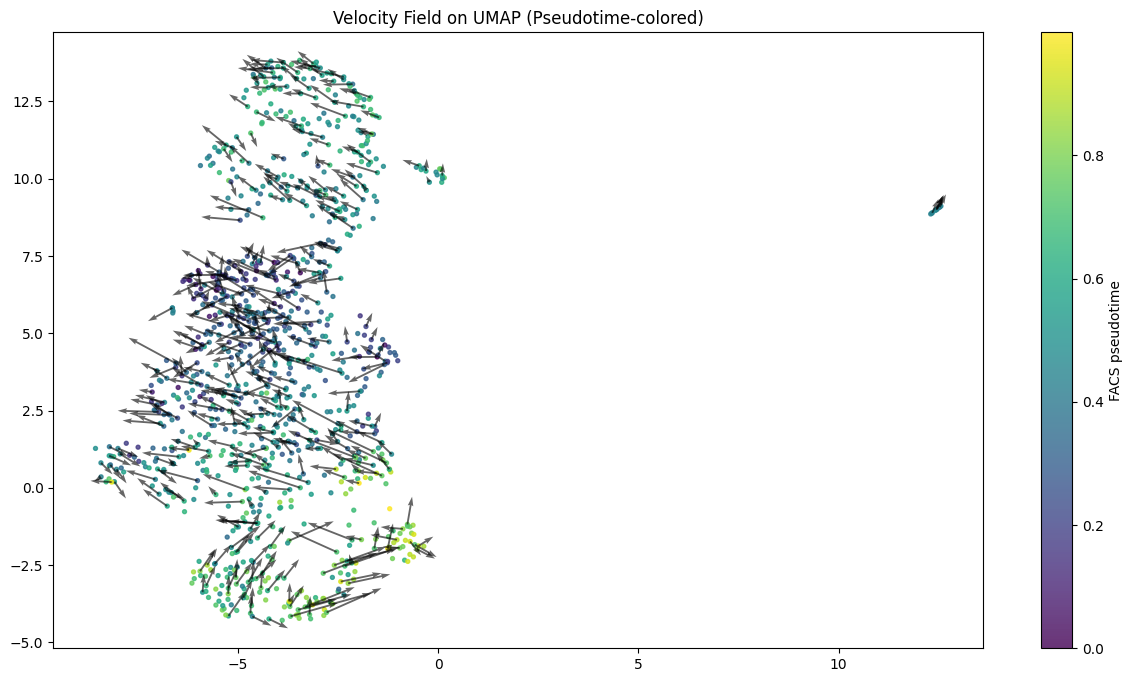

In [43]:
import numpy as np
import matplotlib.pyplot as plt

X_umap = adata.obsm["X_umap"]

pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(15, 8))

sc = ax.scatter(
    X_umap[:, 0], X_umap[:, 1],
    c=pseudo,
    cmap="viridis",
    s=8,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(len(X_umap), 400, replace=False)

ax.quiver(
    X_umap[sample, 0], X_umap[sample, 1],
    V_umap_smooth[sample, 0], V_umap_smooth[sample, 1],
    color="black", alpha=0.6, scale=10, width=0.002
)

ax.set_title("Velocity Field on UMAP (Pseudotime-colored)")
plt.show()

IndexError: index 1008 is out of bounds for axis 0 with size 991

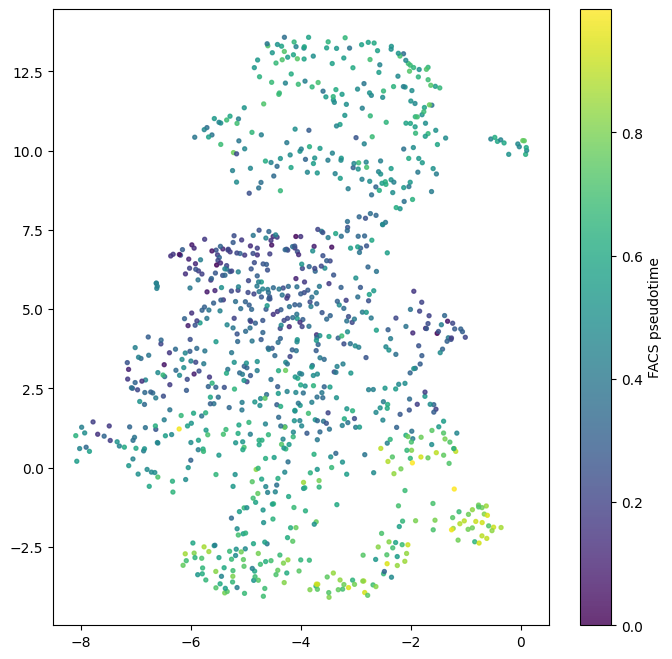

In [44]:
import numpy as np
import matplotlib.pyplot as plt

X_umap = adata.obsm["X_umap"]

pseudo = adata.obs["facs_pseudotime"].values

x, y = X_umap[:, 0], X_umap[:, 1]

x_min, x_max = np.quantile(x, [0.01, 0.99])
y_min, y_max = np.quantile(y, [0.01, 0.99])

mask = (x > x_min) & (x < x_max) & (y > y_min) & (y < y_max)

X_umap_f = X_umap[mask]
V_umap_f = V_umap_smooth[mask]
pseudo_f = pseudo[mask]

fig, ax = plt.subplots(figsize=(8, 8))

sc = ax.scatter(
    X_umap_f[:, 0], X_umap_f[:, 1],
    c=pseudo_f,
    cmap="viridis",
    s=8,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(len(X_umap), 400, replace=False)

ax.quiver(
    X_umap_f[sample, 0], X_umap_f[sample, 1],
    V_umap_f[sample, 0], V_umap_f[sample, 1],
    color="black", alpha=0.6, scale=10, width=0.002
)

ax.set_title("Velocity Field on UMAP (Pseudotime-colored)")
plt.show()

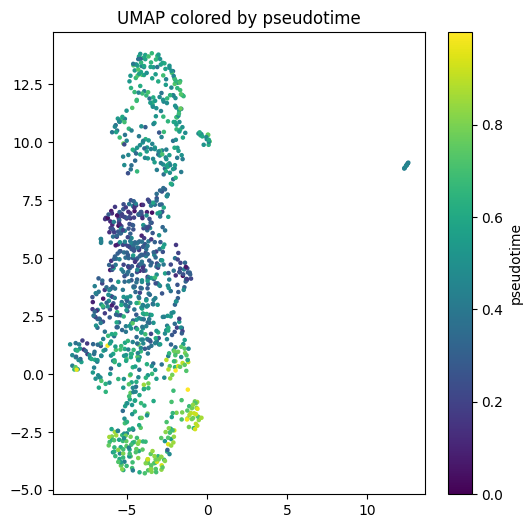

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(X_umap[:,0], X_umap[:,1], c=adata.obs["facs_pseudotime"], s=5)
plt.colorbar(label="pseudotime")
plt.title("UMAP colored by pseudotime")
plt.show()

In [46]:
from scipy.stats import spearmanr

score = spearmanr(
    adata.obs["facs_pseudotime"],
    np.linalg.norm(V_pred, axis=1)
)[0]

print(score)

0.17977388785084605


In [47]:
score = spearmanr(
    adata.obs["facs_pseudotime"],
    (V_pred * X).sum(axis=1)
)[0]
print(score)

-0.22564368290821202


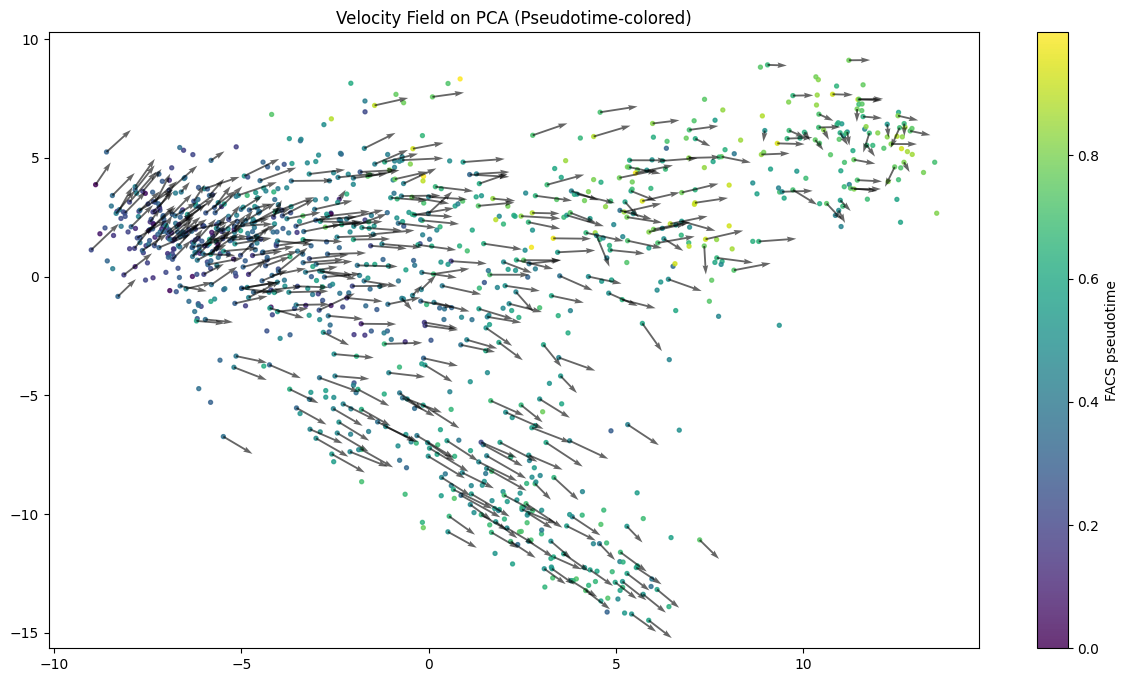

In [48]:
X_pca = adata.obsm["X_pca"][:, :10]  # use first PCs# linear projection of gene velocity into PCA space
V_pca = V_pred @ pca.components_.T[:, :10]
V_pca = -V_pca

from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=30).fit(X_pca)
_, idx = nn.kneighbors(X_pca)

V_pca_smooth = np.array([
    V_pca[idx[i]].mean(axis=0)
    for i in range(len(X_pca))
])

V_pca_smooth = V_pca_smooth / (np.linalg.norm(V_pca_smooth, axis=1, keepdims=True) + 1e-8)
V_pca_smooth *= 0.5

import numpy as np
import matplotlib.pyplot as plt

pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(15, 8))

sc = ax.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=pseudo,
    cmap="viridis",
    s=8,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(len(X_pca), 400, replace=False)

ax.quiver(
    X_pca[sample, 0], X_pca[sample, 1],
    V_pca_smooth[sample, 0], V_pca_smooth[sample, 1],
    color="black", alpha=0.6, scale=10, width=0.002
)

ax.set_title("Velocity Field on PCA (Pseudotime-colored)")
plt.show()

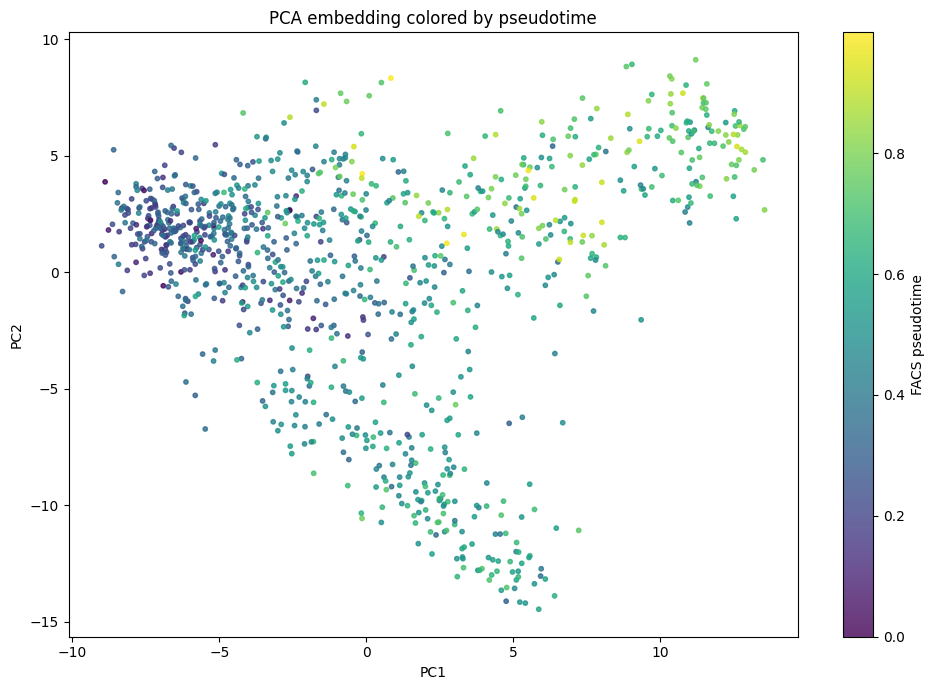

In [49]:
import numpy as np
import matplotlib.pyplot as plt

# PCA embedding
X_pca = adata.obsm["X_pca"][:, :2]

# pseudotime (or swap for any obs label)
pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(10, 7))

sc = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pseudo,
    cmap="viridis",
    s=10,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA embedding colored by pseudotime")

plt.tight_layout()
plt.show()

In [50]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

N = X.shape[0]

nn = NearestNeighbors(n_neighbors=30).fit(X)
neighbors = nn.kneighbors(X, return_distance=False)

def flow_alignment(V_pred, X, neighbors):
    N = X.shape[0]
    scores = []

    for i in range(N):
        vi = V_pred[i]
        vi_norm = np.linalg.norm(vi) + 1e-8

        for j in neighbors[i]:
            dx = X[j] - X[i]

            score = np.dot(vi, dx) / (
                vi_norm * (np.linalg.norm(dx) + 1e-8)
            )
            scores.append(score)

    return np.mean(scores)

score_forward = flow_alignment(V_pred, X, neighbors)
score_backward = flow_alignment(-V_pred, X, neighbors)

print("forward:", score_forward)
print("backward:", score_backward)

forward: 0.36807758
backward: -0.36807758
